In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
import sys
sys.path.append('..')

from src.grid_detection import find_grid_corners, warp_grid
from src.cell_extraction import split_cells

(np.float64(-0.5), np.float64(639.5), np.float64(479.5), np.float64(-0.5))

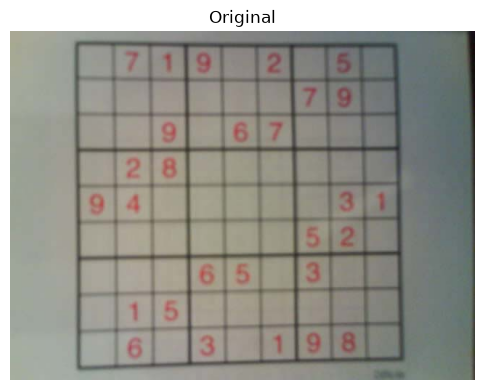

In [ ]:
# Put a sudoku photo/screenshot in data/raw/ first
img = cv2.imread('../data/raw/sample3.png')
plt.figure(figsize=(6,6))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Original')
plt.axis('off')

(np.float64(-0.5), np.float64(639.5), np.float64(479.5), np.float64(-0.5))

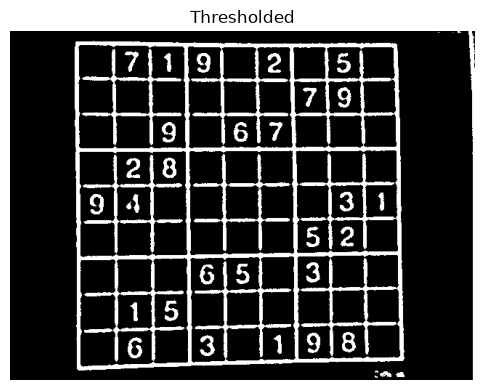

In [ ]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (9, 9), 0)
thresh = cv2.adaptiveThreshold(
    blurred, 255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY_INV,
    11, 2
)

plt.figure(figsize=(6,6))
plt.imshow(thresh, cmap='gray')
plt.title('Thresholded')
plt.axis('off')

(np.float64(-0.5), np.float64(639.5), np.float64(479.5), np.float64(-0.5))

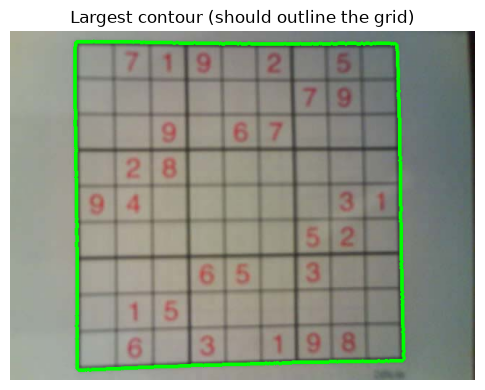

In [ ]:
contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
largest = max(contours, key=cv2.contourArea)

debug_img = img.copy()
cv2.drawContours(debug_img, [largest], -1, (0, 255, 0), 3)

plt.figure(figsize=(6,6))
plt.imshow(cv2.cvtColor(debug_img, cv2.COLOR_BGR2RGB))
plt.title('Largest contour (should outline the grid)')
plt.axis('off')

In [ ]:
def order_corners(pts):
    pts = pts.reshape(4, 2)
    rect = np.zeros((4, 2), dtype='float32')
    s = pts.sum(axis=1)
    rect[0] = pts[np.argmin(s)]   # top-left
    rect[2] = pts[np.argmax(s)]   # bottom-right
    diff = np.diff(pts, axis=1)
    rect[1] = pts[np.argmin(diff)]  # top-right
    rect[3] = pts[np.argmax(diff)]  # bottom-left
    return rect

peri = cv2.arcLength(largest, True)
approx = cv2.approxPolyDP(largest, 0.05 * peri, True)

if len(approx) != 4:
    raise ValueError(f"Expected 4 corners, got {len(approx)} — try adjusting blur/threshold params")

corners = order_corners(approx)
print(corners)

[[ 90.  15.]
 [531.  17.]
 [541. 452.]
 [ 94. 466.]]


(np.float64(-0.5), np.float64(899.5), np.float64(899.5), np.float64(-0.5))

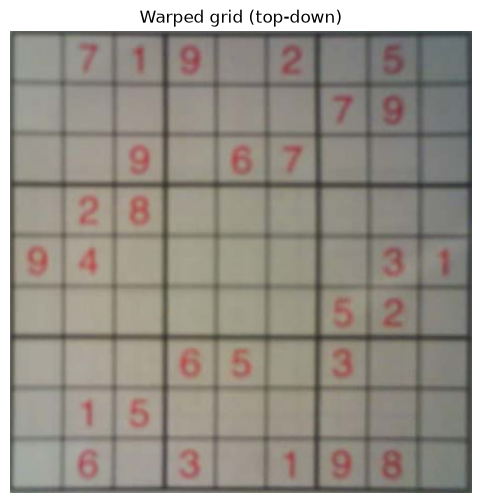

In [ ]:
def warp_grid(img, corners, size=900):
    dst = np.array([
        [0, 0],
        [size - 1, 0],
        [size - 1, size - 1],
        [0, size - 1]
    ], dtype='float32')

    M = cv2.getPerspectiveTransform(corners, dst)
    warped = cv2.warpPerspective(img, M, (size, size))
    return warped, M

warped, M = warp_grid(img, corners)

plt.figure(figsize=(6,6))
plt.imshow(cv2.cvtColor(warped, cv2.COLOR_BGR2RGB))
plt.title('Warped grid (top-down)')
plt.axis('off')

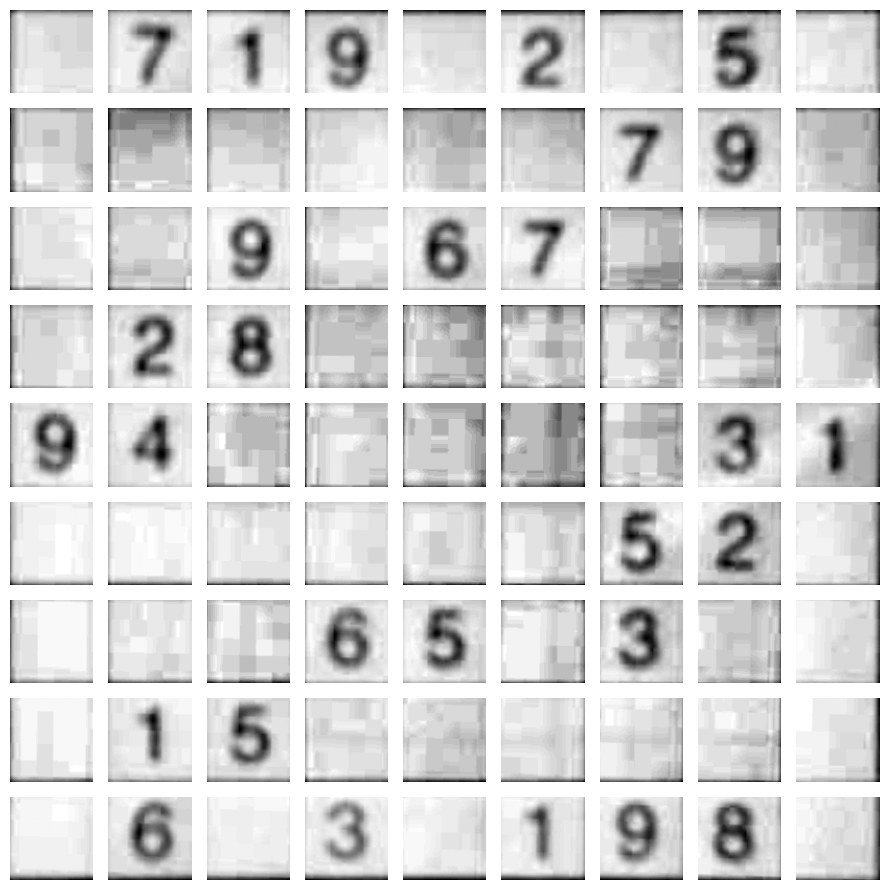

In [ ]:
def split_cells(warped_gray, margin=10):
    size = warped_gray.shape[0]
    cell_size = size // 9
    cells = []
    for row in range(9):
        for col in range(9):
            y1 = row * cell_size + margin
            y2 = (row + 1) * cell_size - margin
            x1 = col * cell_size + margin
            x2 = (col + 1) * cell_size - margin
            cells.append(warped_gray[y1:y2, x1:x2])
    return cells

warped_gray = cv2.cvtColor(warped, cv2.COLOR_BGR2GRAY)
cells = split_cells(warped_gray)

fig, axes = plt.subplots(9, 9, figsize=(9, 9))
for i, ax in enumerate(axes.flat):
    ax.imshow(cells[i], cmap='gray')
    ax.axis('off')
plt.tight_layout()

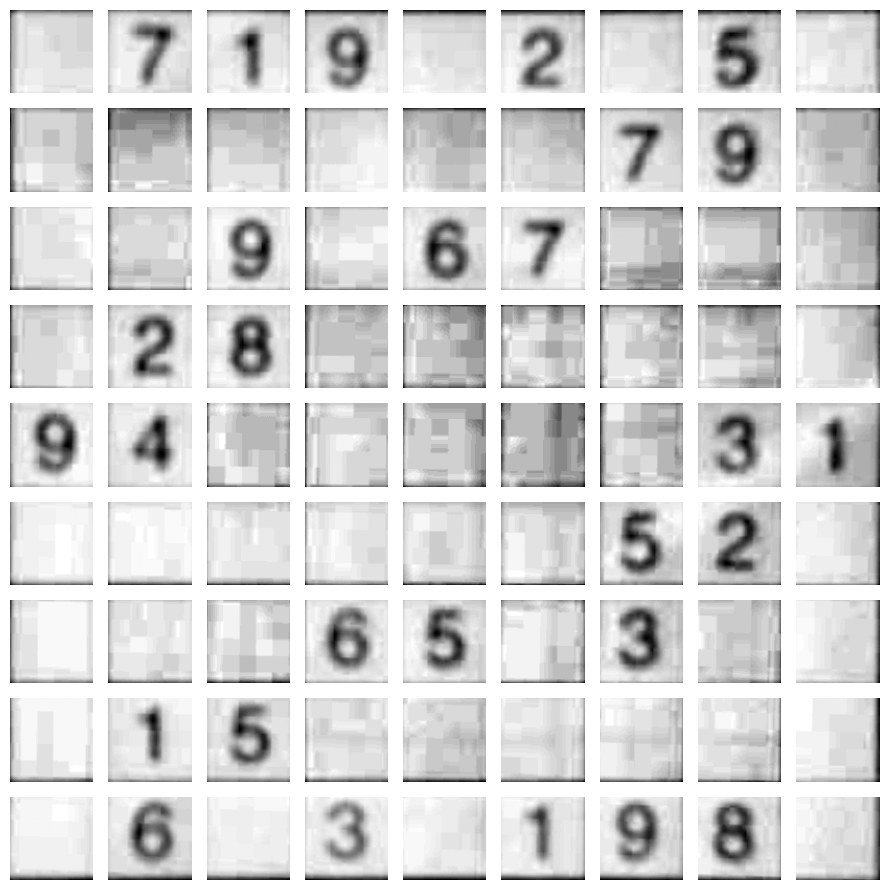

In [ ]:
warped_gray = cv2.cvtColor(warped, cv2.COLOR_BGR2GRAY)
cells = split_cells(warped_gray)

fig, axes = plt.subplots(9, 9, figsize=(9, 9))
for i, ax in enumerate(axes.flat):
    ax.imshow(cells[i], cmap='gray')
    ax.axis('off')
plt.tight_layout()

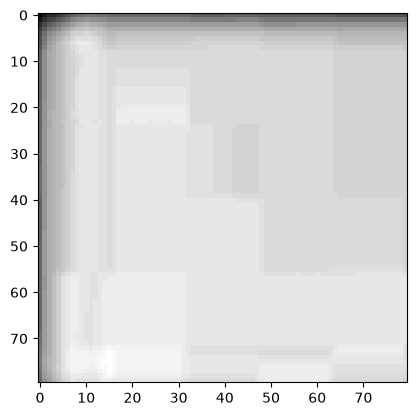

In [ ]:
plt.imshow(cells[0], cmap='gray')

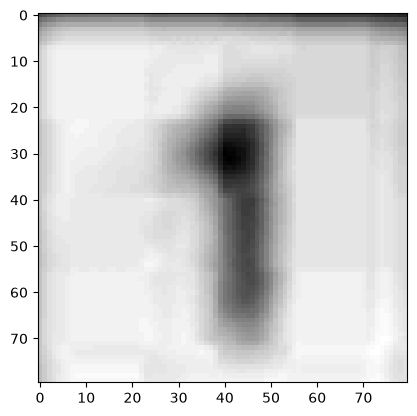

In [ ]:
plt.imshow(cells[2], cmap='gray')